In [ ]:
!pip install contractions datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import contractions
import html

In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [ ]:
# Davidson et al. (2017) Hate Speech and Offensive Language dataset, from Hugging Face
from datasets import load_dataset

df = load_dataset("tdavidson/hate_speech_offensive", split="train").to_pandas()
df.head()


In [ ]:
print(f"Number of rows: {len(df)}")
print(f"Attributes: {df.columns.to_list()}")

Number of rows: 24783
Attributes: ['count', 'hate_speech_count', 'offensive_language_count', 'neither_count', 'class', 'tweet']


In [ ]:
#check the categorical and numerical column name
cat_cols=df.select_dtypes(include=['object']).columns.tolist()
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Categorical Variables:")
print(cat_cols)
print("Numerical Variables:")
print(numeric_columns)

Categorical Variables:
['tweet']
Numerical Variables:
['count', 'hate_speech_count', 'offensive_language_count', 'neither_count', 'class']


In [ ]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   count                     24783 non-null  int64 
 1   hate_speech_count         24783 non-null  int64 
 2   offensive_language_count  24783 non-null  int64 
 3   neither_count             24783 non-null  int64 
 4   class                     24783 non-null  int64 
 5   tweet                     24783 non-null  object
dtypes: int64(5), object(1)
memory usage: 1.1+ MB


,0
count,0
hate_speech_count,0
offensive_language_count,0
neither_count,0
class,0
tweet,0


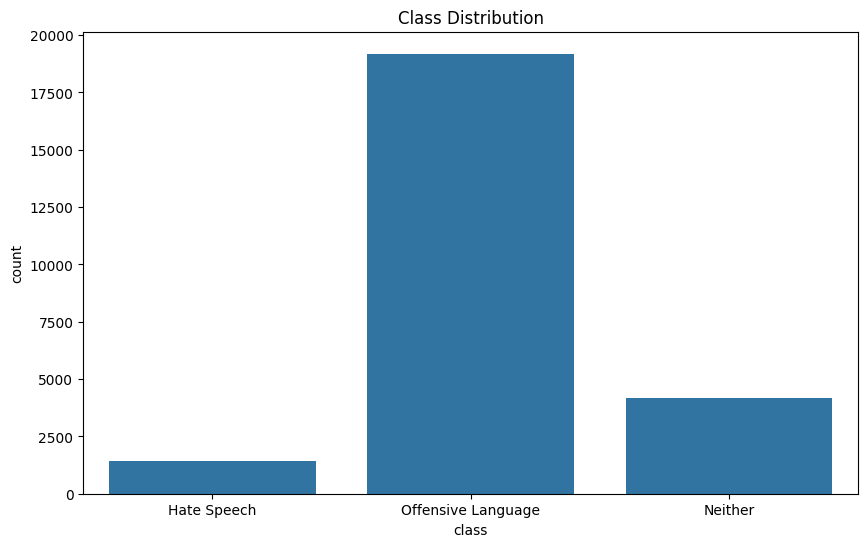

In [ ]:
plt.figure(figsize=(10,6))
ax = sns.countplot(df,x="class")
ax.set_xticks([0,1,2])
ax.set_xticklabels(["Hate Speech", "Offensive Language", "Neither"])
plt.title("Class Distribution")
plt.xlabel("class")
plt.ylabel("count")
plt.show()


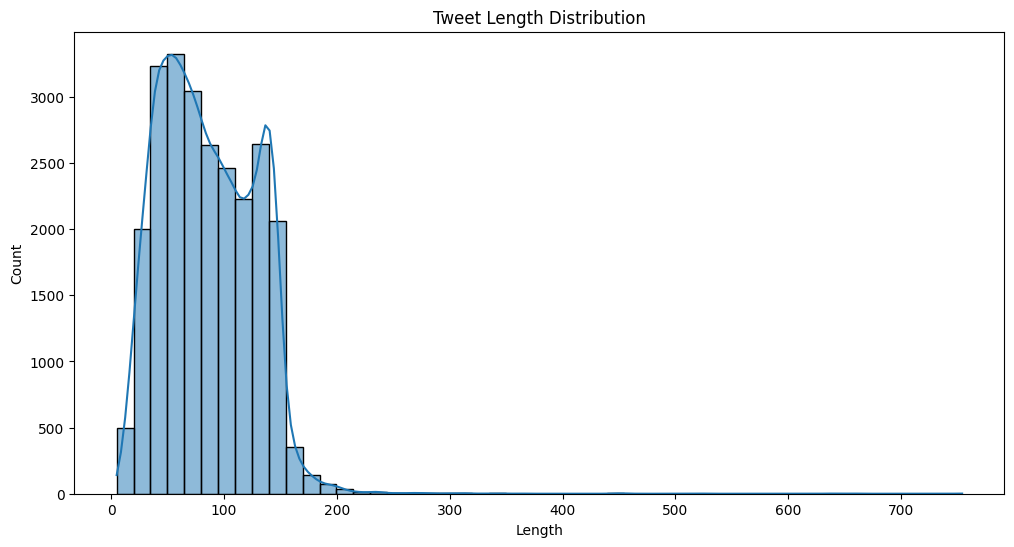

In [ ]:
df["tweet_length"] = df["tweet"].str.len()
plt.figure(figsize=(12,6))
# plt.hist(df["tweet_length"], bins=50)

sns.histplot(df["tweet_length"], bins=50,kde=True)
plt.title("Tweet Length Distribution")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

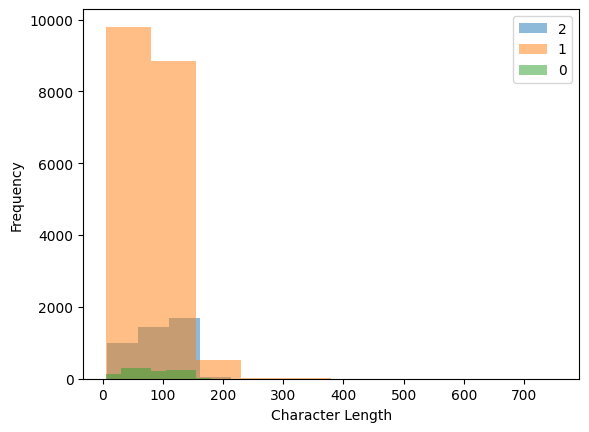

In [ ]:
#tweet length histogram

df['char_length'] = df['tweet'].apply(len)
df['word_length'] = df['tweet'].apply(lambda x: len(x.split()))

# Histogram of character lengths by label
for label in df['class'].unique():
    plt.hist(df[df['class'] == label]['char_length'], alpha=0.5, label=label)
plt.legend()
plt.xlabel('Character Length')
plt.ylabel('Frequency')
plt.show()

In [ ]:
stop_words = set(stopwords.words("english"))
relevant_stopwords = {'not', 'no', 'nor', 'against', 'very', 'ain', 'aren',
                    'couldn', 'didn', 'doesn', 'hadn', 'hasn', 'haven',
                    'isn', 'mightn', 'mustn', 'needn', 'shouldn', 'wasn',
                    'weren', 'won', 'wouldn'}
modified_stopwords = stop_words - relevant_stopwords
lemmatizer = WordNetLemmatizer()

In [ ]:
def process_text(text, stop_words, lemmatizer):
    text = html.unescape(text)
    text = re.sub(r'RT\s+', '', text) #remove rt/RT
    text = re.sub(r'@[A-Za-z0-9_]+', '', text) #remove mentions
    text = contractions.fix(text) # remove contractions
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) #remove urls
    text = re.sub(r'#([A-Za-z0-9_]+)', r'\1', text) #remove hashtags but keep the content
    text = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', text) #added spaces to snakecased words
    text = re.sub(r'&#\d+;?', '', text) #remove emoji codes
    text = re.sub(r'\s+', ' ', text) #remove multiple spaces
    text = text.lower() #lower case tweet
    text = re.compile(r'(\w)(\1{2,})').sub(r'\1', text) #remove repeated characters
    text = re.sub(r'[^\w\s]', ' ', text) # remove punctuations
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words] #remove stopwords and lemmatize
    return ' '.join(tokens)

In [ ]:
df["processed_tweet"] = df["tweet"].apply(lambda t: process_text(t, modified_stopwords, lemmatizer))

In [ ]:
print(df[['tweet', 'processed_tweet']].sample(20, random_state=212121).to_string(index=False), "\n")

In [ ]:
print((df["processed_tweet"] == "").sum())
df = df[df["processed_tweet"] != ""]

2


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer


In [ ]:
#always train test split first, for any learning
X = df['processed_tweet']
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, stratify=y, random_state=42)


#Vectorize the text data using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [ ]:
# display the shapes

print("X_train shape:", X_train_vec.shape)
print("X_test shape:", X_test_vec.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (19824, 15629)
X_test shape: (4957, 15629)
y_train shape: (19824,)
y_test shape: (4957,)


In [ ]:
'''
Random Forest Classifier
'''
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree # Import plot_tree from sklearn.tree
import matplotlib.pyplot as plt




# Implementing Random Forest Classifier
random_forest_model = RandomForestClassifier(n_estimators=100,class_weight='balanced', max_depth = 5,random_state=42)
random_forest_model.fit(X_train_vec, y_train)

# Predictions on the test set
y_pred_rf = random_forest_model.predict(X_test_vec)

# Evaluate the model
print("Random Forest Classifier Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred))

# Visualize one of the decision trees (first tree) in the Forest
# plt.figure(figsize=(60, 40))
# # plot_tree(random_forest_model.estimators_[0], feature_names=vectorizer.get_feature_names_out(), class_names=['Hate Speech', 'Offensive Language', 'Neither'], filled=True, rounded=True)
# plt.title('First Decision Tree Visualization (from Random Forest)')
# plt.show()

Random Forest Classifier Accuracy: 0.8335686907403672
Classification Report:
               precision    recall  f1-score   support

           0       0.32      0.59      0.42       287
           1       0.98      0.83      0.90      3851
           2       0.66      0.95      0.78       819

    accuracy                           0.83      4957
   macro avg       0.65      0.79      0.70      4957
weighted avg       0.89      0.83      0.85      4957

[[   0  283    4]
 [   0 3844    7]
 [   0  647  172]]


In [ ]:
'''
Decision Tree Classifier
'''
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Initialize and train the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(max_depth=10,class_weight='balanced', random_state=42)  # You can adjust hyperparameters here
dt_classifier.fit(X_train_vec, y_train)

# Make predictions on the test set
y_pred = dt_classifier.predict(X_test_vec)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

# Visualize the Decision Tree
# plt.figure(figsize=(60, 40))
# # plot_tree(dt_classifier, feature_names=vectorizer.get_feature_names_out(), class_names=['Hate Speech', 'Offensive Language', 'Neither'], filled=True, rounded=True)
# plt.title('Decision Tree Visualization')
# plt.show()


Accuracy: 0.8069396812588259
Classification Report:
               precision    recall  f1-score   support

           0       0.25      0.42      0.32       287
           1       0.98      0.80      0.88      3851
           2       0.60      0.97      0.74       819

    accuracy                           0.81      4957
   macro avg       0.61      0.73      0.65      4957
weighted avg       0.87      0.81      0.82      4957

[[ 121   54  112]
 [ 347 3084  420]
 [   8   16  795]]


In [ ]:
'''
XGboost

'''
import xgboost as xgb
from xgboost import plot_tree

# Hyperparameters
n_estimators = [50, 100]
learning_rates = [0.01, 0.1, 0.5]

best_model = None
best_accuracy = 0
best_n = 0
best_lr = 0

for n in n_estimators:
    for lr in learning_rates:
        # Set up XGBoost classifier
        xgb_model = xgb.XGBClassifier(
            n_estimators=n,
            learning_rate=lr,
            random_state=42
        )

        # Fit the model
        xgb_model.fit(X_train_vec, y_train)
        y_pred = xgb_model.predict(X_test_vec)

        # Evaluate accuracy
        acc = accuracy_score(y_test, y_pred)
        print(f"n_estimators: {n}, learning_rate: {lr}, Accuracy: {acc:.4f}")

        if acc > best_accuracy:
            best_accuracy = acc
            best_model = xgb_model
            best_n = n
            best_lr = lr

# Final evaluation
print(f"\nBest XGBoost Model: n_estimators={best_n}, learning_rate={best_lr}, Accuracy={best_accuracy:.4f}")
print("Classification Report:\n", classification_report(y_test, best_model.predict(X_test_vec)))
print("Confusion Matrix:\n", confusion_matrix(y_test, best_model.predict(X_test_vec)))

# # Visualize one tree from the best model
# plt.figure(figsize=(15, 10))
# # plot_tree(best_model, num_trees=0)  # Visualizing the first tree in the ensemble
# plt.title("First Tree in XGBoost Model")
# plt.show()


n_estimators: 50, learning_rate: 0.01, Accuracy: 0.8606
n_estimators: 50, learning_rate: 0.1, Accuracy: 0.8987
n_estimators: 50, learning_rate: 0.5, Accuracy: 0.9076
n_estimators: 100, learning_rate: 0.01, Accuracy: 0.8654
n_estimators: 100, learning_rate: 0.1, Accuracy: 0.9060
n_estimators: 100, learning_rate: 0.5, Accuracy: 0.9078

Best XGBoost Model: n_estimators=100, learning_rate=0.5, Accuracy=0.9078
Classification Report:
               precision    recall  f1-score   support

           0       0.51      0.24      0.32       287
           1       0.94      0.95      0.95      3851
           2       0.83      0.92      0.87       819

    accuracy                           0.91      4957
   macro avg       0.76      0.70      0.71      4957
weighted avg       0.90      0.91      0.90      4957

Confusion Matrix:
 [[  68  174   45]
 [  60 3676  115]
 [   5   58  756]]


In [ ]:
'''
Logistic Regression classifier
'''
from sklearn.linear_model import LogisticRegression

lr_classifier = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_classifier.fit(X_train_vec, y_train)

y_pred_lr = lr_classifier.predict(X_test_vec)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))



Logistic Regression Accuracy: 0.8493040145249142
Classification Report:
               precision    recall  f1-score   support

           0       0.31      0.63      0.42       287
           1       0.97      0.85      0.91      3851
           2       0.75      0.94      0.83       819

    accuracy                           0.85      4957
   macro avg       0.68      0.81      0.72      4957
weighted avg       0.90      0.85      0.87      4957

Confusion Matrix:
 [[ 181   59   47]
 [ 379 3258  214]
 [  23   25  771]]


##Support Vector Machine Implementation

              precision    recall  f1-score   support

           0       0.38      0.44      0.41       287
           1       0.95      0.92      0.93      3851
           2       0.81      0.90      0.86       819

    accuracy                           0.89      4957
   macro avg       0.71      0.75      0.73      4957
weighted avg       0.89      0.89      0.89      4957



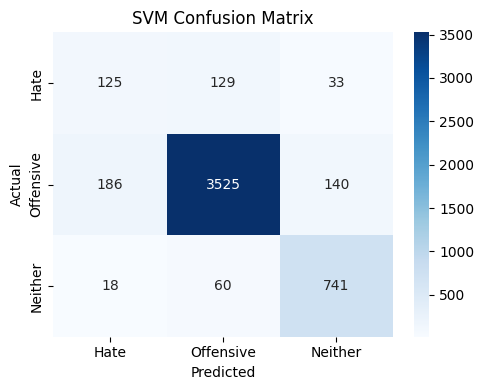

In [ ]:
from sklearn.svm import LinearSVC
svm =  LinearSVC(class_weight='balanced', random_state=42)
svm.fit(X_train_vec,y_train)
y_pred = svm.predict(X_test_vec)
print(classification_report(y_test,y_pred, digits=2))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Hate","Offensive","Neither"],yticklabels=["Hate","Offensive","Neither"])
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best SVM parameter: {'C': 0.1}
              precision    recall  f1-score   support

           0       0.45      0.51      0.48       287
           1       0.96      0.91      0.94      3851
           2       0.77      0.93      0.84       819

    accuracy                           0.89      4957
   macro avg       0.73      0.79      0.75      4957
weighted avg       0.90      0.89      0.89      4957



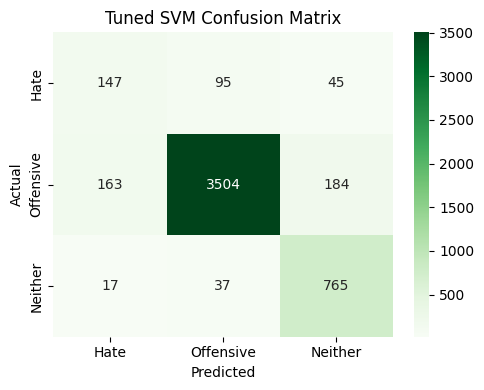

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

param_grid = {"C":[0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LinearSVC(class_weight="balanced", random_state=42),param_grid, cv=5, scoring="f1_macro", n_jobs=-1, verbose=1)
grid.fit(X_train_vec, y_train)
print("Best SVM parameter:",grid.best_params_)
best_svm = grid.best_estimator_

tuned_y_pred = best_svm.predict(X_test_vec)
print(classification_report(y_test, tuned_y_pred, digits=2))

cm2 = confusion_matrix(y_test,  tuned_y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens",xticklabels=["Hate","Offensive","Neither"],yticklabels=["Hate","Offensive","Neither"])
plt.title("Tuned SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Balanced class distribution:
 class
2    1430
1    1430
0    1430
Name: count, dtype: int64 

              precision    recall  f1-score   support

           0       0.72      0.68      0.70       286
           1       0.73      0.77      0.75       286
           2       0.87      0.88      0.87       286

    accuracy                           0.78       858
   macro avg       0.77      0.78      0.77       858
weighted avg       0.77      0.78      0.77       858



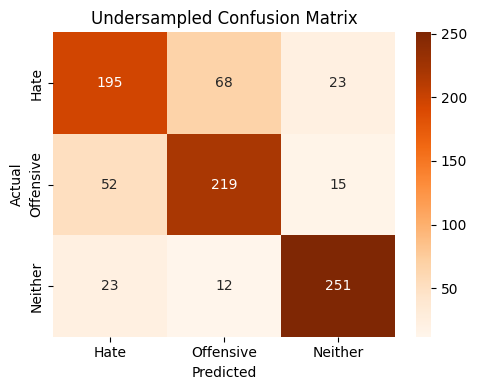

In [ ]:
#Trying UnderSampling

hate_df = df[df['class'] == 0]
offensive_df  = df[df['class'] == 1]
neither_df  = df[df['class'] == 2]
n_hate = len(hate_df)
offensive_down = offensive_df.sample(n=n_hate, random_state=42)
neither_down = neither_df.sample(n=n_hate, random_state=42)

balanced = pd.concat([hate_df, offensive_down, neither_down]).sample(frac=1, random_state=42)
print("Balanced class distribution:\n",balanced['class'].value_counts(),"\n")

X = balanced["processed_tweet"]
y = balanced["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,3), stop_words="english")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
svm = LinearSVC(class_weight="balanced", random_state=42)
svm.fit(X_train_tfidf, y_train)
y_pred = svm.predict(X_test_tfidf)
print(classification_report(y_test, y_pred, digits=2))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",xticklabels=["Hate","Offensive","Neither"],yticklabels=["Hate","Offensive","Neither"])
plt.title("Undersampled Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

RNN

In [ ]:
"Rnn"
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, LSTM, Bidirectional
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


# Tokenization & Padding
max_words = 20000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

train_seq = tokenizer.texts_to_sequences(X_train)
test_seq = tokenizer.texts_to_sequences(X_test)

train_pad = pad_sequences(train_seq, maxlen=max_len, padding='post')
test_pad = pad_sequences(test_seq, maxlen=max_len, padding='post')

# Label Encoding
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = len(le.classes_)
from sklearn.utils import class_weight


# Compute class weights based on training labels
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_enc),
    y=y_train_enc
)

# Convert to dictionary format expected by Keras
# Convert to dictionary format expected by Keras and boost class 0 weight
class_weights = dict(enumerate(class_weights))
class_weights[0] *= 1.5  # Or 2.0 if class 0 is very underrepresented
print("Adjusted class weights:", class_weights)



# RNN Model
embedding_dim = 100 # define the embedding dimension
model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    Bidirectional(SimpleRNN(32)), # Remove input_shape
    Dense(64, activation="relu"),

    Dense(num_classes, activation="softmax")
])



model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(
    train_pad, y_train_enc,
    epochs=5,
    batch_size=64,
    validation_data=(test_pad, y_test_enc),
    class_weight=class_weights
)


# Evaluation with precision, recall, F1
# Evaluation with precision, recall, F1
y_pred = model.predict(test_pad)
y_pred_labels = y_pred.argmax(axis=1)
print(classification_report(y_test_enc, y_pred_labels, target_names=le.classes_.astype(str))) # Convert le.classes_ to strings

Adjusted class weights: {0: 1.5, 1: 1.0, 2: 1.0}
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.3644 - loss: 1.2361 - val_accuracy: 0.5350 - val_loss: 0.9092
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - accuracy: 0.7080 - loss: 0.7551 - val_accuracy: 0.7646 - val_loss: 0.5758
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.8874 - loss: 0.3507 - val_accuracy: 0.7657 - val_loss: 0.6228
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.9596 - loss: 0.1577 - val_accuracy: 0.7576 - val_loss: 0.7418
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 86ms/step - accuracy: 0.9764 - loss: 0.0970 - val_accuracy: 0.7110 - val_loss: 0.8460
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
              precision    recall  f1-score   support

           0       0.58      0.73      0.65       286
           1       0.73      0.66      0.69       286
           2       0.89      0.74      0.81       286

    accuracy                           0.71       858
   macro avg       0.73      0.71      0.72       858
weighted avg 

In [ ]:
"RNN undersampled"
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Bidirectional
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.utils import class_weight
import random
import numpy as np
import tensorflow as tf

# reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# --- 1) LABEL-ENCODE ORIGINAL y_train TO GET y_train_enc FOR RESAMPLING ---

le = LabelEncoder()
y_train_enc_full = le.fit_transform(y_train)  # KEEP FULL ENCODED TRAIN LABELS
num_classes = len(le.classes_)

# --- 2) UNDER-SAMPLE CLASSES 1 AND 2 TO MATCH CLASS 0 COUNT ---
# find indices of each class
idx0 = np.where(y_train_enc_full == 0)[0]
idx1 = np.where(y_train_enc_full == 1)[0]
idx2 = np.where(y_train_enc_full == 2)[0]

n0 = len(idx0)  # target size

# sample without replacement
undersampled_idx1 = np.random.choice(idx1, size=n0, replace=False)
undersampled_idx2 = np.random.choice(idx2, size=n0, replace=False)

# combine indices
resampled_idx = np.concatenate([idx0, undersampled_idx1, undersampled_idx2])
np.random.shuffle(resampled_idx)  # shuffle the order

# build the resampled X_train and y_train
# Use .iloc to select by position, not original index values:
X_train_res = X_train.iloc[resampled_idx].tolist() # Convert to list for tokenizer
y_train_res = y_train_enc_full[resampled_idx]

# --- 3) TOKENIZATION & PADDING ON RESAMPLED TRAIN SET ---
max_words = 20000
max_len   = 100

tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_res)

train_seq = tokenizer.texts_to_sequences(X_train_res)
test_seq  = tokenizer.texts_to_sequences(X_test)  # X_test stays intact

train_pad = pad_sequences(train_seq, maxlen=max_len, padding='post')
test_pad  = pad_sequences(test_seq,  maxlen=max_len, padding='post')

# --- 4) PREPARE y_test ENCODING ---
y_test_enc = le.transform(y_test)  # use same encoder

# --- 5) COMPUTE & ADJUST CLASS WEIGHTS ON THE RESAMPLED TRAINING SET ---
class_weights_arr = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_res),
    y=y_train_res
)
class_weights = dict(enumerate(class_weights_arr))
# if you still want to boost class 0 further:
class_weights[0] *= 1.5

print("Adjusted class weights:", class_weights)

# --- 6) BUILD & TRAIN THE MODEL ---
embedding_dim = 100

model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    Bidirectional(SimpleRNN(32)),
    Dense(64, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(
    train_pad, y_train_res,
    epochs=5,
    batch_size=64,
    validation_data=(test_pad, y_test_enc),
    class_weight=class_weights
)

# --- 7) EVALUATION ---
y_pred = model.predict(test_pad)
y_pred_labels = np.argmax(y_pred, axis=1)

print(
    classification_report(
        y_test_enc,
        y_pred_labels,
        target_names=le.classes_.astype(str)
    )
)

Adjusted class weights: {0: 1.5, 1: 1.0, 2: 1.0}
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.3070 - loss: 1.2462 - val_accuracy: 0.4860 - val_loss: 0.9683
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.6671 - loss: 0.8765 - val_accuracy: 0.7611 - val_loss: 0.5761
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.9213 - loss: 0.2895 - val_accuracy: 0.7448 - val_loss: 0.6843
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.9699 - loss: 0.1238 - val_accuracy: 0.7587 - val_loss: 0.7669
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.9893 - loss: 0.0603 - val_accuracy: 0.7529 - val_loss: 0.8476
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
              precision    recall  f1-score   support

           0       0.75      0.56      0.64       286
           1       0.68      0.78      0.73       286
           2       0.83      0.93      0.87       286

    accuracy                           0.75       858
   macro avg       0.75      0.75      0.75       858
weighted avg 

In [ ]:
"5-fold cross-over RNN"
import numpy as np
import pandas as pd
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Bidirectional
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.utils import class_weight

# Set seeds
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Full dataset
X = df['processed_tweet']
y = df['class']

# Split once: 80% train, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Encode labels for test set
le = LabelEncoder()
y_test_enc = le.fit_transform(y_test)
num_classes = len(le.classes_)

# Tokenizer setup
max_words = 20000
max_len = 100
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_full)

X_test_seq = tokenizer.texts_to_sequences(X_test)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# Cross-validation setup
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold = 1
all_preds = []

for train_idx, val_idx in skf.split(X_train_full, y_train_full):
    print(f"\nFold {fold}")

    X_train = X_train_full.iloc[train_idx]
    y_train = y_train_full.iloc[train_idx]
    X_val = X_train_full.iloc[val_idx]
    y_val = y_train_full.iloc[val_idx]

    # Tokenize and pad
    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_val_seq = tokenizer.texts_to_sequences(X_val)

    X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
    X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post')

    # Encode labels
    y_train_enc = le.transform(y_train)
    y_val_enc = le.transform(y_val)

    # Compute class weights & boost class 0
    weights = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train_enc),
        y=y_train_enc
    )
    class_weights = dict(enumerate(weights))
    class_weights[0] *= 1.5  # Boost class 0

    # RNN Model
    model = Sequential([
        Embedding(input_dim=max_words, output_dim=100, input_length=max_len),
        Bidirectional(SimpleRNN(32)),
        Dense(64, activation="relu"),
        Dense(num_classes, activation="softmax")
    ])

    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

    model.fit(
        X_train_pad, y_train_enc,
        validation_data=(X_val_pad, y_val_enc),
        epochs=5,
        batch_size=64,
        class_weight=class_weights,
        verbose=2
    )

    fold += 1

# Final evaluation on the held-out test set
y_test_pred_probs = model.predict(X_test_pad)
y_test_preds = y_test_pred_probs.argmax(axis=1)
print("\nFinal Test Set Performance:")
print(classification_report(y_test_enc, y_test_preds, target_names=le.classes_.astype(str)))



Fold 1


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
248/248 - 34s - 136ms/step - accuracy: 0.5125 - loss: 0.9308 - val_accuracy: 0.8557 - val_loss: 0.4618
Epoch 2/5
248/248 - 18s - 75ms/step - accuracy: 0.8432 - loss: 0.4054 - val_accuracy: 0.8535 - val_loss: 0.4125
Epoch 3/5
248/248 - 24s - 98ms/step - accuracy: 0.9174 - loss: 0.1897 - val_accuracy: 0.8358 - val_loss: 0.4522
Epoch 4/5
248/248 - 36s - 143ms/step - accuracy: 0.9572 - loss: 0.1025 - val_accuracy: 0.8593 - val_loss: 0.4625
Epoch 5/5
248/248 - 20s - 82ms/step - accuracy: 0.9716 - loss: 0.0646 - val_accuracy: 0.8618 - val_loss: 0.5255

Fold 2
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 24s - 95ms/step - accuracy: 0.5625 - loss: 0.9682 - val_accuracy: 0.5770 - val_loss: 0.8421
Epoch 2/5
248/248 - 22s - 87ms/step - accuracy: 0.8023 - loss: 0.4803 - val_accuracy: 0.7695 - val_loss: 0.6067
Epoch 3/5
248/248 - 19s - 76ms/step - accuracy: 0.9213 - loss: 0.1739 - val_accuracy: 0.8313 - val_loss: 0.4933
Epoch 4/5
248/248 - 21s - 84ms/step - accuracy: 0.9618 - loss: 0.0827 - val_accuracy: 0.8578 - val_loss: 0.4966
Epoch 5/5
248/248 - 20s - 81ms/step - accuracy: 0.9794 - loss: 0.0479 - val_accuracy: 0.8646 - val_loss: 0.5441

Fold 3
Epoch 1/5


...

248/248 - 23s - 92ms/step - accuracy: 0.5548 - loss: 0.9591 - val_accuracy: 0.6928 - val_loss: 0.7945
Epoch 2/5
248/248 - 19s - 76ms/step - accuracy: 0.8280 - loss: 0.4329 - val_accuracy: 0.7596 - val_loss: 0.6358
Epoch 3/5
248/248 - 21s - 86ms/step - accuracy: 0.9296 - loss: 0.1519 - val_accuracy: 0.7856 - val_loss: 0.6091
Epoch 4/5
248/248 - 19s - 76ms/step - accuracy: 0.9667 - loss: 0.0746 - val_accuracy: 0.7929 - val_loss: 0.6813
Epoch 5/5
248/248 - 18s - 71ms/step - accuracy: 0.9758 - loss: 0.0553 - val_accuracy: 0.8237 - val_loss: 0.6466

Fold 4
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 22s - 91ms/step - accuracy: 0.5141 - loss: 1.0218 - val_accuracy: 0.5198 - val_loss: 0.8868
Epoch 2/5
248/248 - 19s - 75ms/step - accuracy: 0.8061 - loss: 0.4894 - val_accuracy: 0.6752 - val_loss: 0.7737
Epoch 3/5
248/248 - 21s - 86ms/step - accuracy: 0.9265 - loss: 0.1599 - val_accuracy: 0.7821 - val_loss: 0.6595
Epoch 4/5
248/248 - 20s - 79ms/step - accuracy: 0.9598 - loss: 0.0993 - val_accuracy: 0.8113 - val_loss: 0.6622
Epoch 5/5
248/248 - 20s - 82ms/step - accuracy: 0.9744 - loss: 0.0583 - val_accuracy: 0.8207 - val_loss: 0.6918

Fold 5
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 22s - 88ms/step - accuracy: 0.4165 - loss: 1.0838 - val_accuracy: 0.7722 - val_loss: 0.6850
Epoch 2/5
248/248 - 21s - 85ms/step - accuracy: 0.8057 - loss: 0.4890 - val_accuracy: 0.7603 - val_loss: 0.6615
Epoch 3/5
248/248 - 19s - 77ms/step - accuracy: 0.9127 - loss: 0.1863 - val_accuracy: 0.8274 - val_loss: 0.5162
Epoch 4/5
248/248 - 21s - 84ms/step - accuracy: 0.9569 - loss: 0.0921 - val_accuracy: 0.8585 - val_loss: 0.4717
Epoch 5/5
248/248 - 21s - 85ms/step - accuracy: 0.9719 - loss: 0.0616 - val_accuracy: 0.8375 - val_loss: 0.5617
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step

Final Test Set Performance:
              precision    recall  f1-score   support

           0       0.23      0.38      0.29       286
           1       0.93      0.87      0.90      3838
           2       0.78      0.83      0.81       833

    accuracy                           0.83      4957
   macro avg       0.65      0.69      0.66      4957
weighted avg       0.86      0.83      0.85      4957

In [ ]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Bidirectional
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.utils import class_weight

# ─── 0) Seeds ────────────────────────────────────────────────────────────────
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# ─── 1) Split off a held-out test set ────────────────────────────────────────
X = df['processed_tweet']
y = df['class']
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ─── 2) Under-sample classes 1 & 2 to focus on class 0 ──────────────────────
# encode y_train_full
le = LabelEncoder()
y_train_enc_full = le.fit_transform(y_train_full)
num_classes = len(le.classes_)

# find indices by class
idx0 = np.where(y_train_enc_full == 0)[0]
idx1 = np.where(y_train_enc_full == 1)[0]
idx2 = np.where(y_train_enc_full == 2)[0]
n0   = len(idx0)

# sample 1 & 2 down to size of class 0
undersamp1 = np.random.choice(idx1, size=n0, replace=False)
undersamp2 = np.random.choice(idx2, size=n0, replace=False)

# build balanced training arrays
bal_idx = np.concatenate([idx0, undersamp1, undersamp2])
np.random.shuffle(bal_idx)

X_train_bal = X_train_full.iloc[bal_idx].reset_index(drop=True)
y_train_bal = y_train_enc_full[bal_idx]

# ─── 3) Prepare test set ────────────────────────────────────────────────────
y_test_enc = le.transform(y_test)

# ─── 4) Tokenizer (fit on full train if you want full vocab) ───────────────
max_words = 20000
max_len   = 100
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_full)

X_test_seq = tokenizer.texts_to_sequences(X_test)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# ─── 5) 5-Fold CV on the balanced set ───────────────────────────────────────
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold = 1

for train_idx, val_idx in skf.split(X_train_bal, y_train_bal):
    print(f"\n>>> Fold {fold} <<<")
    X_tr = X_train_bal.iloc[train_idx]
    y_tr = y_train_bal[train_idx]
    X_val = X_train_bal.iloc[val_idx]
    y_val = y_train_bal[val_idx]

    # tokenize & pad
    tr_seq  = tokenizer.texts_to_sequences(X_tr)
    val_seq = tokenizer.texts_to_sequences(X_val)
    X_tr_pad  = pad_sequences(tr_seq,  maxlen=max_len, padding='post')
    X_val_pad = pad_sequences(val_seq, maxlen=max_len, padding='post')

    # optional: recompute & boost class-0 weight
    weights = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_tr),
        y=y_tr
    )
    cw = dict(enumerate(weights))
    cw[0] *= 2.0   # e.g. double emphasis on class 0

    # build & compile
    model = Sequential([
        Embedding(input_dim=max_words, output_dim=100, input_length=max_len),
        Bidirectional(SimpleRNN(32)),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    # train
    model.fit(
        X_tr_pad, y_tr,
        validation_data=(X_val_pad, y_val),
        epochs=5,
        batch_size=64,
        class_weight=cw,
        verbose=2
    )
    fold += 1

# ─── 6) Final evaluation on the original test set ──────────────────────────
y_test_pred = model.predict(X_test_pad).argmax(axis=1)
print("\n=== Test Set Classification Report ===")
print(classification_report(y_test_enc, y_test_pred, target_names=le.classes_.astype(str)))



>>> Fold 1 <<<
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


43/43 - 9s - 220ms/step - accuracy: 0.3508 - loss: 1.3261 - val_accuracy: 0.4440 - val_loss: 0.9734
Epoch 2/5
43/43 - 4s - 83ms/step - accuracy: 0.6568 - loss: 0.9011 - val_accuracy: 0.7656 - val_loss: 0.6123
Epoch 3/5
43/43 - 5s - 119ms/step - accuracy: 0.9056 - loss: 0.3636 - val_accuracy: 0.7540 - val_loss: 0.6264
Epoch 4/5
43/43 - 5s - 121ms/step - accuracy: 0.9577 - loss: 0.1859 - val_accuracy: 0.7729 - val_loss: 0.6718
Epoch 5/5
43/43 - 3s - 65ms/step - accuracy: 0.9825 - loss: 0.0921 - val_accuracy: 0.7627 - val_loss: 0.7455

>>> Fold 2 <<<
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


43/43 - 8s - 197ms/step - accuracy: 0.3319 - loss: 1.3683 - val_accuracy: 0.3348 - val_loss: 1.0866
Epoch 2/5
43/43 - 3s - 81ms/step - accuracy: 0.6284 - loss: 0.9105 - val_accuracy: 0.6812 - val_loss: 0.6984
Epoch 3/5
43/43 - 5s - 122ms/step - accuracy: 0.9188 - loss: 0.3109 - val_accuracy: 0.6812 - val_loss: 0.7455
Epoch 4/5
43/43 - 5s - 118ms/step - accuracy: 0.9811 - loss: 0.0921 - val_accuracy: 0.6725 - val_loss: 0.8062
Epoch 5/5
43/43 - 5s - 118ms/step - accuracy: 0.9923 - loss: 0.0414 - val_accuracy: 0.6856 - val_loss: 0.8673

>>> Fold 3 <<<
Epoch 1/5


...

43/43 - 7s - 172ms/step - accuracy: 0.3325 - loss: 1.3753 - val_accuracy: 0.3397 - val_loss: 1.0594
Epoch 2/5
43/43 - 5s - 126ms/step - accuracy: 0.6202 - loss: 0.9420 - val_accuracy: 0.7012 - val_loss: 0.6722
Epoch 3/5
43/43 - 3s - 74ms/step - accuracy: 0.8969 - loss: 0.3720 - val_accuracy: 0.7391 - val_loss: 0.6394
Epoch 4/5
43/43 - 5s - 113ms/step - accuracy: 0.9669 - loss: 0.1340 - val_accuracy: 0.7187 - val_loss: 0.7219
Epoch 5/5
43/43 - 6s - 140ms/step - accuracy: 0.9825 - loss: 0.0659 - val_accuracy: 0.7143 - val_loss: 0.8033

>>> Fold 4 <<<
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


43/43 - 7s - 166ms/step - accuracy: 0.3332 - loss: 1.3914 - val_accuracy: 0.3324 - val_loss: 1.0963
Epoch 2/5
43/43 - 4s - 92ms/step - accuracy: 0.5688 - loss: 1.0167 - val_accuracy: 0.6720 - val_loss: 0.7400
Epoch 3/5
43/43 - 4s - 93ms/step - accuracy: 0.9031 - loss: 0.3773 - val_accuracy: 0.6910 - val_loss: 0.7422
Epoch 4/5
43/43 - 3s - 66ms/step - accuracy: 0.9738 - loss: 0.1235 - val_accuracy: 0.7362 - val_loss: 0.7362
Epoch 5/5
43/43 - 6s - 144ms/step - accuracy: 0.9891 - loss: 0.0550 - val_accuracy: 0.7143 - val_loss: 0.8631

>>> Fold 5 <<<
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


43/43 - 8s - 188ms/step - accuracy: 0.3358 - loss: 1.3949 - val_accuracy: 0.3382 - val_loss: 1.1034
Epoch 2/5
43/43 - 4s - 91ms/step - accuracy: 0.5510 - loss: 1.0905 - val_accuracy: 0.5379 - val_loss: 1.0066
Epoch 3/5
43/43 - 3s - 68ms/step - accuracy: 0.8252 - loss: 0.6118 - val_accuracy: 0.6385 - val_loss: 0.8624
Epoch 4/5
43/43 - 3s - 68ms/step - accuracy: 0.9355 - loss: 0.2616 - val_accuracy: 0.6793 - val_loss: 0.8635
Epoch 5/5
43/43 - 3s - 64ms/step - accuracy: 0.9778 - loss: 0.1011 - val_accuracy: 0.6603 - val_loss: 0.9720
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step

=== Test Set Classification Report ===
              precision    recall  f1-score   support

           0       0.13      0.77      0.23       286
           1       0.93      0.62      0.74      3838
           2       0.61      0.54      0.57       833

    accuracy                           0.61      4957
   macro avg       0.56      0.64      0.51      4957
weighted avg       0.83      0.61      0.68      4957



In [ ]:
import numpy as np
import pandas as pd
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Bidirectional, LSTM,  Dropout
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn.utils import class_weight

# Set seeds
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Full dataset
X = df['processed_tweet']
y = df['class']

# Split once: 80% train, 20% test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

le = LabelEncoder()
y_test_enc = le.fit_transform(y_test)
num_classes = len(le.classes_)

max_words = 20000
max_len = 100
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_full)

X_test_seq = tokenizer.texts_to_sequences(X_test)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# Cross-validation setup
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold = 1
all_preds = []

for train_idx, val_idx in skf.split(X_train_full, y_train_full):
    print(f"\nFold {fold}")

    X_train = X_train_full.iloc[train_idx]
    y_train = y_train_full.iloc[train_idx]
    X_val = X_train_full.iloc[val_idx]
    y_val = y_train_full.iloc[val_idx]

    # Tokenize and pad
    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_val_seq = tokenizer.texts_to_sequences(X_val)

    X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
    X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post')

    # Encode labels
    y_train_enc = le.transform(y_train)
    y_val_enc = le.transform(y_val)

    # Compute class weights & boost class 0
    weights = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train_enc),
        y=y_train_enc
    )
    class_weights = dict(enumerate(weights))
    class_weights[0] *= 1.5  # Boost class 0

    # LSTM Model


    # LSTM Model (tuned)
    model = Sequential([
        Embedding(input_dim=max_words, output_dim=128, input_length=max_len),  # Increased embedding dimension
        Bidirectional(LSTM(64, return_sequences=True, dropout=0.3, recurrent_dropout=0.3)),
        Bidirectional(LSTM(32, dropout=0.3, recurrent_dropout=0.3)),  # Stacked LSTM
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])



    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

    model.fit(
        X_train_pad, y_train_enc,
        validation_data=(X_val_pad, y_val_enc),
        epochs=5,
        batch_size=64,
        class_weight=class_weights,
        verbose=2
    )

    fold += 1

y_test_pred_probs = model.predict(X_test_pad)
y_test_preds = y_test_pred_probs.argmax(axis=1)
print("\nFinal Test Set Performance:")
print(classification_report(y_test_enc, y_test_preds, target_names=le.classes_.astype(str)))



Fold 1
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 162s - 655ms/step - accuracy: 0.4660 - loss: 0.9684 - val_accuracy: 0.8515 - val_loss: 0.4812
Epoch 2/5
248/248 - 202s - 816ms/step - accuracy: 0.8135 - loss: 0.5202 - val_accuracy: 0.8366 - val_loss: 0.4963
Epoch 3/5
248/248 - 200s - 805ms/step - accuracy: 0.8657 - loss: 0.3435 - val_accuracy: 0.8469 - val_loss: 0.4783
Epoch 4/5
248/248 - 202s - 814ms/step - accuracy: 0.9017 - loss: 0.2463 - val_accuracy: 0.8628 - val_loss: 0.4613
Epoch 5/5
248/248 - 204s - 823ms/step - accuracy: 0.9208 - loss: 0.1865 - val_accuracy: 0.8502 - val_loss: 0.5033

Fold 2
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 164s - 660ms/step - accuracy: 0.5761 - loss: 0.9540 - val_accuracy: 0.7538 - val_loss: 0.7573
Epoch 2/5
248/248 - 200s - 805ms/step - accuracy: 0.7934 - loss: 0.5387 - val_accuracy: 0.7690 - val_loss: 0.6606
Epoch 3/5
248/248 - 141s - 567ms/step - accuracy: 0.8542 - loss: 0.3454 - val_accuracy: 0.8159 - val_loss: 0.5375
Epoch 4/5
248/248 - 143s - 578ms/step - accuracy: 0.8991 - loss: 0.2412 - val_accuracy: 0.8391 - val_loss: 0.5097
Epoch 5/5
248/248 - 140s - 566ms/step - accuracy: 0.9195 - loss: 0.1866 - val_accuracy: 0.8262 - val_loss: 0.6009

Fold 3
Epoch 1/5


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


248/248 - 163s - 658ms/step - accuracy: 0.4955 - loss: 0.9964 - val_accuracy: 0.8058 - val_loss: 0.6434
Epoch 2/5
248/248 - 137s - 554ms/step - accuracy: 0.7965 - loss: 0.5410 - val_accuracy: 0.7730 - val_loss: 0.5842
Epoch 3/5


KeyboardInterrupt: 

BERT

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from torch.optim import AdamW
from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup
from tqdm.auto import tqdm

# 0. Detect device (GPU if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cpu':
    print("Warning: Running on CPU. To enable GPU, install CUDA-enabled PyTorch (e.g., `pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118`)")

le = LabelEncoder()
df['label'] = le.fit_transform(df['class'])  # e.g. hate=0, offensive=1, neither=2
classes = np.unique(df['label'])

train_df, val_df = train_test_split(df,test_size=0.1,stratify=df['label'],random_state=42)


class_weights = compute_class_weight(class_weight='balanced',classes=classes,y=train_df['label'])
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

tokenizer = BertTokenizerFast.from_pretrained('bert-base-uncased')
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 3

class HateSpeechDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'labels': torch.tensor(label, dtype=torch.long)
        }


train_dataset = HateSpeechDataset(train_df['processed_tweet'].tolist(),train_df['label'].values,tokenizer,MAX_LEN)
sample_weights = [1.0 / class_weights[label].item() for label in train_df['label'].tolist()]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,sampler=sampler)

val_dataset = HateSpeechDataset(val_df['tweet'].tolist(),val_df['label'].values,tokenizer,MAX_LEN)
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE * 2,shuffle=False)


model = BertForSequenceClassification.from_pretrained('bert-base-uncased',num_labels=len(classes))
model.to(device)
optimizer = AdamW(model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer,num_warmup_steps=0,num_training_steps=total_steps)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

for epoch in range(EPOCHS):
    model.train()
    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    total_loss = 0
    for batch in loop:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids, attention_mask=attention_mask)
        loss = loss_fn(outputs.logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
        loop.set_postfix(loss=total_loss/(loop.n+1))
    print(f"Epoch {epoch+1} | Avg Loss: {total_loss/len(train_loader):.4f}")


model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for batch in tqdm(val_loader, desc="Evaluating"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=le.classes_,
        digits=4
    )
)

model.save_pretrained("models/bert_hate_baseline")
tokenizer.save_pretrained("models/bert_hate_baseline")
print("Training & evaluation complete.")


c:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


C:\Users\user\AppData\Local\Temp\ipykernel_14476\2465195467.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['label'] = le.fit_transform(df['class'])  # e.g. hate=0, offensive=1, neither=2
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Epoch 1/3: 100%|██████████| 1394/1394 [10:06<00:00,  2.30it/s, loss=0.277]


Epoch 1 | Avg Loss: 0.2766


Epoch 2/3: 100%|██████████| 1394/1394 [10:21<00:00,  2.24it/s, loss=0.194]


...

Epoch 3/3: 100%|██████████| 1394/1394 [10:22<00:00,  2.24it/s, loss=0.174]


Epoch 3 | Avg Loss: 0.1740


Evaluating: 100%|██████████| 78/78 [00:24<00:00,  3.23it/s]



Classification Report:


TypeError: object of type 'numpy.int64' has no len()

In [ ]:
from sklearn.metrics import classification_report

# Ensure model is in eval mode
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Make sure class names are strings
target_names = [str(cls) for cls in le.classes_]

print("\nClassification Report:\n")
print(classification_report(
    all_labels,
    all_preds,
    target_names=target_names,
    digits=4
))



Classification Report:

              precision    recall  f1-score   support

           0     0.7500    0.0210    0.0408       143
           1     0.9005    0.9854    0.9411      1920
           2     0.9011    0.8101    0.8532       416

    accuracy                         0.9004      2479
   macro avg     0.8505    0.6055    0.6117      2479
weighted avg     0.8919    0.9004    0.8744      2479

